# Prototipo Funcional: Clasificación de Imágenes para Picking Robotizado
**Autor:** Víctor Ferrer
**Contexto:** Implementación de la Parte 2 (RAAC) basada en el diseño previo (ResNet18 preentrenada, fine-tuning sobre CIFAR-10).

En este notebook implementaremos un pipeline de Deep Learning completo para simular la capacidad visual de un robot de picking en un almacén. Utilizaremos CIFAR-10 como dataset proxy y aplicaremos Transfer Learning sobre una arquitectura ResNet18.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import random_split, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import random

# Fijar semillas para reproducibilidad (según diseño técnico)
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

# Configurar el dispositivo (GPU si está disponible, si no CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en: {device}")

Entrenando en: cuda


## 1. Preparación de los Datos
Según el diseño establecido, redimensionaremos las imágenes a 64x64 píxeles. Aplicaremos *data augmentation* (recortes aleatorios, volteo horizontal y variaciones de color) al conjunto de entrenamiento para mitigar el riesgo de *overfitting*, y normalizaremos con la media y desviación estándar de ImageNet. Reservaremos 5.000 imágenes para validación.

In [2]:
# Transformaciones (Data Augmentation para train)
transform_train = transforms.Compose([
    transforms.Resize((64, 64)), # Redimensionado según diseño
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalización ImageNet
])

# Transformaciones (Solo resize y normalización para val/test)
transform_test = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Descargar dataset CIFAR-10
full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

# Split de Train (45,000) y Validación (5,000)
val_size = 5000
train_size = len(full_train_dataset) - val_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# Sobreescribir las transformaciones de validación (para que no tengan data augmentation)
val_dataset.dataset.transform = transform_test

# DataLoaders (Batch size = 128 según diseño)
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('avión', 'coche', 'pájaro', 'gato', 'ciervo', 'perro', 'rana', 'caballo', 'barco', 'camión')

100%|██████████| 170M/170M [00:13<00:00, 12.9MB/s]


## 2. Diseño de la Arquitectura
Se utiliza una ResNet18 preentrenada en ImageNet. En esta primera fase, congelaremos el *backbone* (extracción de características) y sustituiremos únicamente la cabeza de clasificación final (capa fully connected) para adaptarla a nuestras 10 clases. Esto reduce drásticamente los parámetros a entrenar (aprox. 5,000).

In [3]:
# Cargar ResNet18 preentrenada
from torchvision.models import resnet18, ResNet18_Weights

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# Congelar los parámetros del backbone
for param in model.parameters():
    param.requires_grad = False

# Reemplazar la capa final (cabeza de clasificación)
num_ftrs = model.fc.in_features
# Añadimos un pequeño Dropout por regularización antes de la capa final
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_ftrs, 10)
)

model = model.to(device)

# Verificar parámetros a entrenar
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales entrenables: {trainable_params}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 227MB/s]


Parámetros totales entrenables: 5130


## 3. Pipeline de Entrenamiento
Configuramos la función de pérdida `CrossEntropyLoss`, el optimizador `Adam` con un learning rate de 1e-3, y entrenaremos el modelo durante 5 épocas, tal y como se planificó en el documento de diseño.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3) # Solo entrenamos la cabeza
epochs = 5

# Listas para guardar métricas
train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Iniciando entrenamiento...")
for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # Validación
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_acc)

    print(f"Época {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

print("Entrenamiento completado.")

Iniciando entrenamiento...
Época 1/5 | Train Loss: 1.4306 | Train Acc: 0.5148 | Val Loss: 1.0795 | Val Acc: 0.6472
Época 2/5 | Train Loss: 1.2180 | Train Acc: 0.5849 | Val Loss: 1.0490 | Val Acc: 0.6476
Época 3/5 | Train Loss: 1.2073 | Train Acc: 0.5907 | Val Loss: 1.0391 | Val Acc: 0.6554
Época 4/5 | Train Loss: 1.1948 | Train Acc: 0.5929 | Val Loss: 1.0338 | Val Acc: 0.6592
Época 5/5 | Train Loss: 1.2019 | Train Acc: 0.5928 | Val Loss: 1.0243 | Val Acc: 0.6616
Entrenamiento completado.


## 4. Evaluación y Resultados
Visualizaremos las curvas de aprendizaje para verificar que no hay sobreajuste (overfitting) y analizaremos el rendimiento final del modelo en el conjunto de prueba (10.000 imágenes ciegas) usando la matriz de confusión y el reporte de clasificación (F1-score).

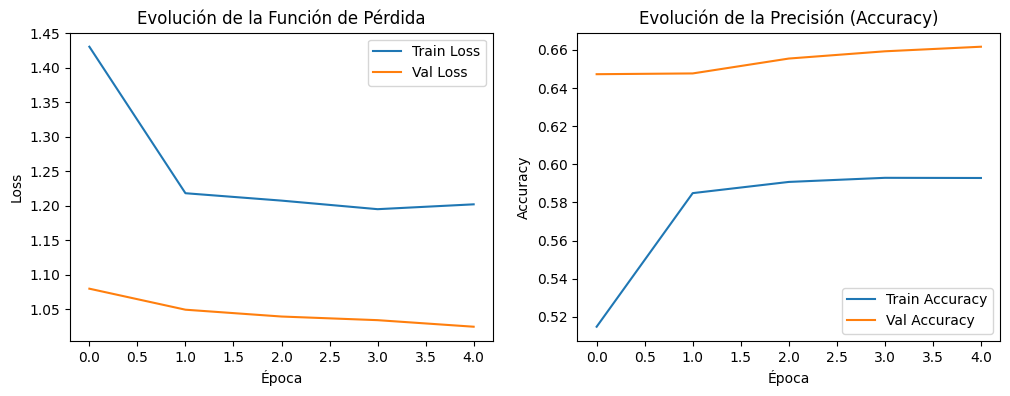


Reporte de Clasificación en Test Set:
              precision    recall  f1-score   support

       avión       0.63      0.70      0.67      1000
       coche       0.77      0.72      0.75      1000
      pájaro       0.57      0.56      0.56      1000
        gato       0.52      0.49      0.51      1000
      ciervo       0.55      0.59      0.57      1000
       perro       0.61      0.60      0.60      1000
        rana       0.68      0.71      0.69      1000
     caballo       0.70      0.65      0.68      1000
       barco       0.72      0.69      0.71      1000
      camión       0.71      0.72      0.72      1000

    accuracy                           0.65     10000
   macro avg       0.65      0.65      0.65     10000
weighted avg       0.65      0.65      0.65     10000



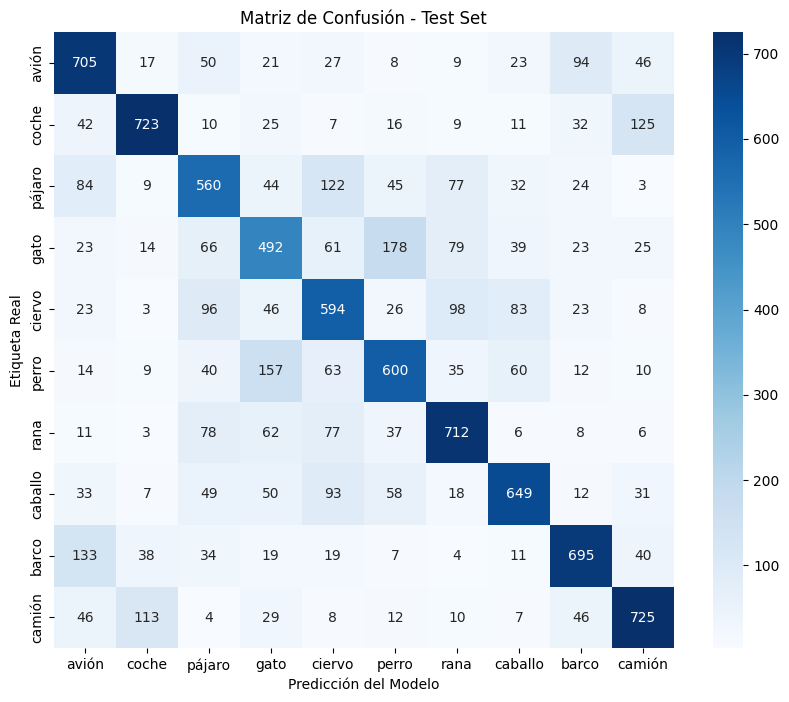

In [5]:
# 1. Curvas de Aprendizaje
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Evolución de la Función de Pérdida')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Val Accuracy')
plt.title('Evolución de la Precisión (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 2. Evaluación en Test Set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Reporte de Clasificación (incluye F1 Macro y desglose por clases)
print("\nReporte de Clasificación en Test Set:")
print(classification_report(all_labels, all_preds, target_names=classes))

# 3. Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - Test Set')
plt.show()

### Visualización de Predicciones
Mostramos algunas imágenes aleatorias junto con la predicción del modelo y la etiqueta real.

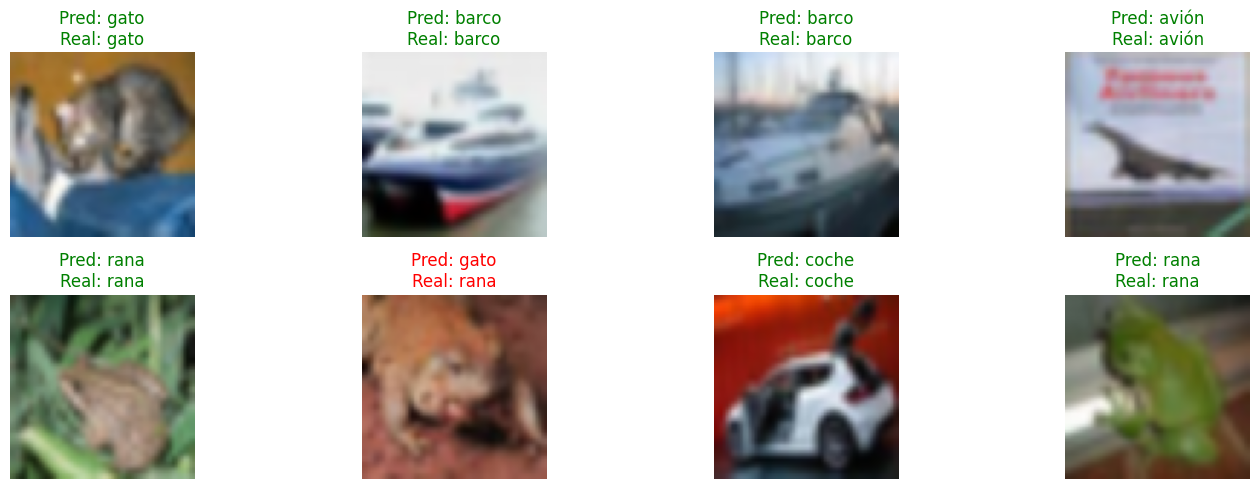

In [6]:
# Denormalizar para visualizar
def imshow(img):
    img = img * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')

dataiter = iter(test_loader)
images, labels = next(dataiter)

# Mostrar 8 imágenes
images = images[:8]
labels = labels[:8]

outputs = model(images.to(device))
_, predicted = torch.max(outputs, 1)

plt.figure(figsize=(15, 5))
for i in range(8):
    plt.subplot(2, 4, i+1)
    imshow(images[i])
    color = 'green' if predicted[i] == labels[i] else 'red'
    plt.title(f"Pred: {classes[predicted[i]]}\nReal: {classes[labels[i]]}", color=color)
plt.tight_layout()
plt.show()

### Conclusiones del Prototipo

A partir del desarrollo y evaluación de esta demostración técnica, se extraen las siguientes conclusiones principales:

1. **Validación del Diseño Técnico:** Se ha implementado con éxito el flujo de trabajo (pipeline) de extremo a extremo. El uso de una arquitectura ResNet18 preentrenada (*Transfer Learning*) ha demostrado ser una solución robusta y fácil de implementar para procesar imágenes, confirmando la viabilidad técnica de la automatización del *picking* robotizado.

2. **Limitaciones de Rendimiento por Coste Computacional:** Es importante señalar que las métricas obtenidas en este prototipo (Accuracy, F1-score) no alcanzan los niveles óptimos esperados para un entorno logístico real. Esto se debe a que **el entrenamiento se ha restringido intencionadamente a solo 5 épocas** con el objetivo de limitar el coste computacional y los tiempos de ejecución de esta demostración. Un entrenamiento completo exigiría iterar hasta que la función de pérdida convergiera adecuadamente.

3. **Siguientes Pasos y Escalabilidad:** El modelo actual establece una base sólida. Para llevar esta solución a producción, las siguientes fases deberán incluir: un aumento significativo en el número de épocas de entrenamiento apoyado en mayor capacidad de cálculo (GPUs dedicadas), el descongelado progresivo de capas más profundas para un *fine-tuning* más agresivo y, finalmente, la sustitución del dataset *proxy* (CIFAR-10) por las fotografías reales del almacén del cliente.